In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, cross_val_predict, cross_validate
from sklearn.linear_model import LinearRegression
from scipy.stats import gaussian_kde

sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENT_LOOKUP_DICT, ENSEMBLE_MEMBERS, CATCHMENTS

from PrepDataFunctions import *

### Get event data

In [2]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
# df[df['max_quartile_index_n'].isnull()][["max_precip", "max_quartile_index_n", "length", "total_acc", "length_of_active_rain"]]
# df = create_subset(df, 10000, 10)
subset_early = create_temporal_subset(df, "before", 2020)

### Create version of model with all variables included

In [3]:
rf = RandomForestRegressor(n_estimators=800, min_samples_leaf = 2, max_depth=16,max_samples = None, max_features = 1.0, 
                           random_state=42)
lr = LinearRegression()
cv_parameters = KFold(n_splits=5, shuffle=True, random_state=42)
error_metrics = ['neg_mean_absolute_error', 'r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_percentage_error']



In [4]:
predictor_variables = [col for col in subset_early.columns if col not in ['10cm_area', '10cm_volume', '30cm_area', '30cm_volume']]

# Define X (predictors) and Y (response)
X = subset_early[predictor_variables]
y = subset_early['10cm_area']

In [5]:
y_pred_lr = cross_val_predict(lr, X, y, cv=cv_parameters)
y_pred_rf = cross_val_predict(rf, X, y, cv=cv_parameters)

In [ ]:
# all_variables_r2_lr = cross_val_score(lr, X, y, cv=cv_parameters, scoring='r2').mean()
# print(f"Full model R²: {all_variables_r2_lr:.4f}")

# all_variables_r2_rf = cross_val_score(rf, X, y, cv=cv_parameters, scoring='r2').mean()
# print(f"Full model R²: {all_variables_r2_rf:.4f}")

In [6]:
all_variables_r2_lr = cross_val_score(lr, X, y, cv=cv_parameters, scoring='r2').mean()
print(f"Full model R²: {all_variables_r2_lr:.4f}")

all_variables_r2_rf = cross_val_score(rf, X, y, cv=cv_parameters, scoring='r2').mean()
print(f"Full model R²: {all_variables_r2_rf:.4f}")

Full model R²: 0.6112
Full model R²: 0.8607


In [ ]:
# # Use cross_validate to return the error scores associated with this model and this data
# model_output = cross_validate(rf, X, y, cv=cv_parameters, scoring=error_metrics, error_score="raise")

# # Formulate the different error scores into a dataframe
# error_metrics_df =pd.DataFrame({'mae': round(abs(model_output['test_neg_mean_absolute_error'].mean()),2), 
#               'mape': round(abs(model_output['test_neg_mean_absolute_percentage_error'].mean()),2),
#               'r2': round(abs(model_output['test_r2'].mean()),2), 
#               'rmse': round(abs(model_output['test_neg_root_mean_squared_error'].mean()),2)}, index =["RF"])

# error_metrics_df

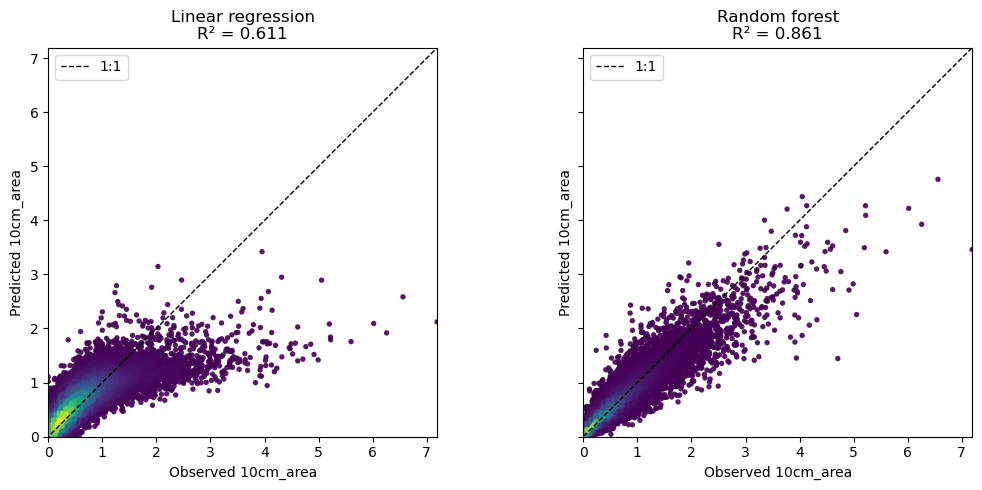

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)

for ax, y_pred, name, r2 in zip(axes,
    [y_pred_lr, y_pred_rf],
    ['Linear regression', 'Random forest'],[all_variables_r2_lr, all_variables_r2_rf]):
    xy = np.vstack([y,y_pred])
    z = gaussian_kde(xy)(xy)
    ax.scatter(y, y_pred, alpha=0.9, s=15, c = z, edgecolor='none')
    
    # using_datashader(axs[0], y, y_pred, 'linear')
    
    # 1:1 reference line
    lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
    ax.plot(lims, lims, 'k--', linewidth=1, label='1:1')
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    
    ax.set_xlabel('Observed 10cm_area')
    ax.set_ylabel('Predicted 10cm_area')
    ax.set_title(f'{name}\nR² = {r2:.3f}')
    ax.set_aspect('equal')
    ax.legend()

plt.tight_layout()
plt.show()

### Investigate which parts of the distribution for each variable are most benefitted by RF over LR

In [ ]:
results = subset.copy()
results['y_true'] = y.values
results['pred_lr'] = y_pred_lr
results['pred_rf'] = y_pred_rf

results['abs_err_lr'] = (results['y_true'] - results['pred_lr']).abs()
results['abs_err_rf'] = (results['y_true'] - results['pred_rf']).abs()

# Positive = RF does better at this point (smaller error)
results['rf_improvement'] = results['abs_err_lr'] - results['abs_err_rf']

results_sorted = results.sort_values('rf_improvement', ascending=False)

In [ ]:
top_rf_wins = results_sorted.head(50)      # RF much better
top_lr_wins = results_sorted.tail(50)      # LR much better (or RF much worse)

# top_rf_wins[predictor_variables + ['y_true', 'pred_lr', 'pred_rf']].describe()

Think the problem with this is that it's hard to distinguish between whether presence of lots of blue/red points is due to the majority of the points being concentrated in those areas in general, or because there is actually a disproportionate number of RF/LR wins there. 

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(18, 8))
key_vars = ['max_precip', 'fu_at_peak_new', 'fu_at_peak_old','mean_sm_2_before_event', 'lu_at_peak','fumax_at_peak',
            'total_acc', 'dry_ratio', 'peak_position_ratio', 'gini', 'd50', 'start_year', "cluster_n_cells_t50",
           "length", "length_of_active_rain"]

for ax, var in zip(axes.flat, key_vars):
    ax.scatter(results[var], results['rf_improvement'], alpha=0.2, s=10, color='grey')
    ax.scatter(top_rf_wins[var], top_rf_wins['rf_improvement'], alpha=0.7, s=15, color='crimson', label='RF wins')
    ax.scatter(top_lr_wins[var], top_lr_wins['rf_improvement'], alpha=0.7, s=15, color='steelblue', label='LR wins')
    ax.axhline(0, color='k', linewidth=0.5)
    ax.set_xlabel(var)

axes.flat[0].legend()
plt.tight_layout()
plt.show()

In [ ]:
def enrichment_plot(var, data_full, data_red, n_bins=10, ax=None):
    bins = np.quantile(data_full[var].dropna(), np.linspace(0, 1, n_bins + 1))
    bins = np.unique(bins)  # in case of repeated values (e.g. fu_at_peak_new)
    
    full_counts, _ = np.histogram(data_full[var].dropna(), bins=bins)
    red_counts, _ = np.histogram(data_red[var].dropna(), bins=bins)
    
    full_frac = full_counts / full_counts.sum()
    red_frac = red_counts / red_counts.sum()
    
    enrichment = red_frac / full_frac  # >1 means over-represented among RF wins
    
    bin_centers = (bins[:-1] + bins[1:]) / 2
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(bin_centers, enrichment, width=np.diff(bins)*0.9)
    ax.axhline(1, color='k', linewidth=1, linestyle='--')
    ax.set_xlabel(var)
    ax.set_ylabel('Enrichment (red / overall)')
    return ax

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, var in zip(axes.flat, key_vars):
    enrichment_plot(var, results, top_rf_wins, ax=ax)
plt.tight_layout()
plt.show()

## Using SHAP

In [8]:
import shap 
rf.fit(X,y)
explainer = shap.TreeExplainer(rf)

In [ ]:
shap_values = explainer.shap_values(X)

# Global summary: which variables matter most overall, and in which direction
shap.summary_plot(shap_values, X, show=True, max_display=70)

In [ ]:
# Source - https://stackoverflow.com/a/70479829
# Posted by mozway
# Retrieved 2026-10-06, License - CC BY-SA 4.0

# subset.corrwith(subset['peak_cell_inside_prop'])[:50]